# CAREMap · 04 Michigan licensed-slot model

v2, step 1. Notebook 03 showed that the national childcare measure (young children per childcare *worker*) tracks Michigan's licensed *slots* only moderately. This notebook rebuilds Michigan's childcare side from licensed slots and asks:

1. How differently do the two measures rank Michigan's counties?
2. Where they disagree, what explains it?
3. Does using licensed slots change which Michigan counties look like candidates?

It starts with a data check, because the state's licensing file has a problem that limits what it can be used for.

**Caveats.** Licensed capacity covers ages 0-12, not just under 5. License-exempt care (relatives, some school programs) is not in the licensing file. Licensing is current (late 2026); the national measure uses 2023 business data. All comparisons are *within Michigan*.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

scores = pd.read_csv(ROOT / "data/processed/county_scores_v1.csv", dtype={"GEOID": str})
join = pd.read_csv(ROOT / "data/processed/county_v1_join.csv", dtype={"GEOID": str})
lic = pd.read_csv(ROOT / "data/raw/mi_licensed_childcare_v2.csv", dtype={"GEOID": str})
lic["Capacity"] = pd.to_numeric(lic["Capacity"], errors="coerce")
print(f"{len(lic):,} licensed providers, {lic['Capacity'].sum():,.0f} licensed slots")

7,700 licensed providers, 396,960 licensed slots


## 0. Data check: the state file's county and capacity columns are attached to the wrong providers

Each provider record has a name, address and map point, plus a county name and a capacity. Placing every map point inside its real county boundary shows the county column almost never matches the location. One example: a family home on Hayes Tower Rd in Gaylord (Otsego County) is listed as being in Kent County with 226 slots, which is impossible for a home licensed for up to 6 or 7 children. A second state copy that covers Wayne County only lists that county's homes at 6 or 7 slots each, as expected.

In [2]:
shp = ROOT / "data/raw/manual/cb_2024_us_county_5m.zip"
counties = gpd.read_file(f"zip://{shp}")
counties = counties[counties["STATEFP"] == "26"].to_crs(4326)[["GEOID", "geometry"]].rename(columns={"GEOID": "GEOID_loc"})
pts = gpd.GeoDataFrame(lic, geometry=gpd.points_from_xy(lic["Longitude"], lic["Latitude"]), crs=4326)
lic = gpd.sjoin(pts, counties, how="left", predicate="within").drop(columns=["index_right", "geometry"]).sort_index()

ok = lic["GEOID_loc"].notna()
print(f"County column agrees with the map point for {(lic.loc[ok, 'GEOID'] == lic.loc[ok, 'GEOID_loc']).mean():.1%} of providers")

County column agrees with the map point for 5.8% of providers


The useful finding is *how* it is wrong. Three tests:

1. **Counts by county still match.** Counting providers by the county column gives the same county totals as counting by map point. So the county column is the right list of counties, shuffled across rows.
2. **Capacity is the real list too, shuffled.** Exactly as many records have a capacity of 7 or less as there are family homes (licensed for 6-7), and about as many fall in 8-14 as there are group homes (licensed for 12-14).
3. **County and capacity were shuffled together.** If they had been shuffled separately, every county's average capacity would look like a random draw. Instead, county averages vary far more than random draws would (permutation test below), so each county name still sits next to its own capacity.

**What this means:** county totals of licensed slots are trustworthy, which is what notebook 03 and this notebook use. Any provider-level link between capacity and location is not. That rules out placing *capacity* in census tracts directly; the tract step below has to estimate it.

In [3]:
by_col = lic.groupby("GEOID").size().rename("by county column")
by_pt = lic.groupby("GEOID_loc").size().rename("by map point")
cnt = pd.concat([by_col, by_pt], axis=1).fillna(0)
print(f"1. Provider counts per county, column vs map point: correlation {cnt.corr().iloc[0, 1]:.4f}, "
      f"largest difference {int((cnt.iloc[:, 0] - cnt.iloc[:, 1]).abs().max())} providers")

n_family, n_group = (lic["FacilityTypeCode"] == "DF").sum(), (lic["FacilityTypeCode"] == "DG").sum()
print(f"2. Capacity of 7 or less: {(lic['Capacity'] <= 7).sum():,} records; family homes: {n_family:,}")
print(f"   Capacity 8-14: {lic['Capacity'].between(8, 14).sum():,} records; group homes: {n_group:,}")


def between_var(df):
    g = df.groupby("GEOID")["Capacity"]
    return ((g.mean() - df["Capacity"].mean()) ** 2 * g.size()).sum()


rng = np.random.default_rng(0)
obs = between_var(lic)
null = np.array([between_var(lic.assign(Capacity=rng.permutation(lic["Capacity"].values))) for _ in range(500)])
print(f"3. Between-county spread in average capacity: observed {obs:,.0f}; "
      f"if shuffled separately, 95% of draws below {np.percentile(null, 95):,.0f} (p < {1/len(null):.3f})")

1. Provider counts per county, column vs map point: correlation 1.0000, largest difference 3 providers
2. Capacity of 7 or less: 1,771 records; family homes: 1,771
   Capacity 8-14: 1,421 records; group homes: 1,380


3. Between-county spread in average capacity: observed 1,669,311; if shuffled separately, 95% of draws below 376,400 (p < 0.002)


## 1. Build the licensed-slot measure

County totals use the county column (trustworthy, per the check above). The split between home-based and center slots uses capacity size, which travels with the county name: 14 or fewer slots = a home (a handful of very small centers get counted as homes), more = a center. Children per licensed slot is smoothed for small counties with the same empirical-Bayes method as the national score (notebook 02).

In [4]:
lic["home_by_size"] = lic["Capacity"] <= 14
cty = lic.groupby("GEOID").agg(licensed_slots=("Capacity", "sum"),
                               home_slots=("Capacity", lambda s: s[s <= 14].sum()))
cty["home_share"] = cty["home_slots"] / cty["licensed_slots"]
# provider types counted by map point (names, types and points are consistent with each other)
types = lic.groupby(["GEOID_loc", "FacilityTypeCode"]).size().unstack(fill_value=0)
types = types.rename(columns={"DC": "centers_n", "DF": "family_homes_n", "DG": "group_homes_n"})
types["licensed_homes_n"] = types["family_homes_n"] + types["group_homes_n"]
cty = cty.join(types, how="left").reset_index()

mi = (scores[(scores["USPS"] == "MI") & (scores["tier"] != "Not scored")]
      .merge(join[["GEOID", "cbp_emp", "cbp_estab", "nes_estab"]], on="GEOID", how="left")
      .merge(cty, on="GEOID", how="left"))
mi["high_if_zero"] = mi["high_if_zero"].astype(str).eq("True")
mi["cbp_withheld_0to2"] = mi["cbp_withheld_0to2"].astype(str).eq("True")


def eb_rate(count, base):
    count, base = count.astype(float), base.astype(float)
    r0 = count.sum() / base.sum()
    raw = count / base
    between = max(raw.var() - (r0 / base).mean(), 1e-12)
    m = r0 / between
    return (count + m * r0) / (base + m), m


mi["kids_per_slot_eb"], m = eb_rate(mi["kids_under5"], mi["licensed_slots"])
print(f"Michigan counties scored: {len(mi)}; smoothing strength m = {m:.1f}")
print(f"Counties at 3+ young children per licensed slot (a common 'desert' line): {(mi['kids_per_slot_eb'] >= 3).sum()}")

# both measures as within-Michigan percentiles, 100 = worst shortage
mi["lic_score_mi"] = mi["kids_per_slot_eb"].rank(pct=True) * 100
mi["proxy_score_mi"] = mi["kpw_low_eb"].rank(pct=True) * 100
mi[["kids_per_slot_eb", "lic_score_mi", "proxy_score_mi", "home_share"]].describe().round(2)

Michigan counties scored: 82; smoothing strength m = 3.2
Counties at 3+ young children per licensed slot (a common 'desert' line): 3


,kids_per_slot_eb,lic_score_mi,proxy_score_mi,home_share
count,82.00,82.00,82.00,82.00
mean,1.66,50.61,50.61,0.15
std,0.63,29.04,29.04,0.12
min,0.90,1.22,1.22,0.00
25%,1.29,25.91,25.91,0.08
50%,1.57,50.61,50.61,0.12
75%,1.87,75.30,75.30,0.18
max,5.56,100.00,100.00,0.74


## 2. How differently do they rank Michigan?

Rank correlation between the two shortage scores, plus agreement on the worst quarter of counties.

In [5]:
def agree(d):
    rho = d["lic_score_mi"].rank().corr(d["proxy_score_mi"].rank())
    q = max(1, round(len(d) * 0.25))
    a, b = set(d.nlargest(q, "lic_score_mi")["GEOID"]), set(d.nlargest(q, "proxy_score_mi")["GEOID"])
    return pd.Series({"counties": len(d), "rank correlation": round(rho, 2), "worst-quarter overlap": f"{len(a & b)} of {q}"})

summary = pd.DataFrame({
    "All Michigan": agree(mi),
    "Metro": agree(mi[mi["group"] == "Metro"]),
    "Rural": agree(mi[mi["group"] == "Nonmetro"]),
    "Business data published": agree(mi[~mi["cbp_withheld_0to2"]]),
    "Business data withheld": agree(mi[mi["cbp_withheld_0to2"]]),
}).T
summary

,counties,rank correlation,worst-quarter overlap
All Michigan,82,0.62,13 of 20
Metro,30,0.62,5 of 8
Rural,52,0.59,4 of 13
Business data published,70,0.5,10 of 18
Business data withheld,12,0.22,0 of 3


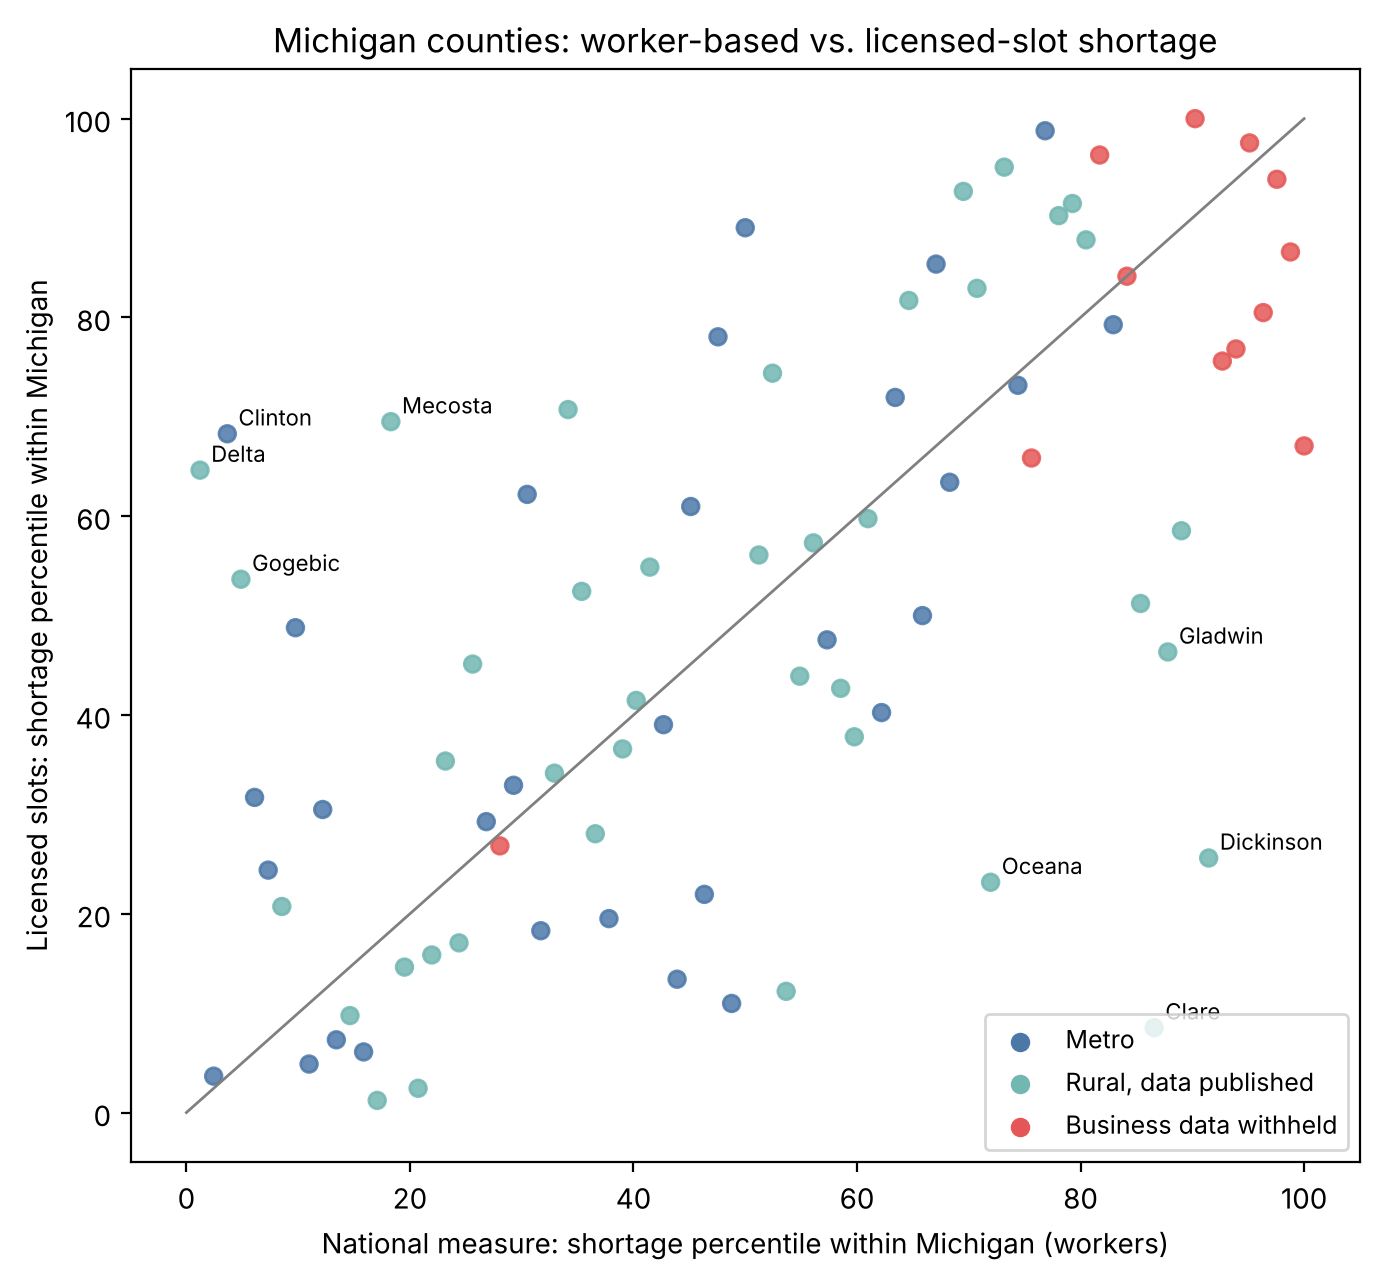

In [6]:
mi["rank_gap"] = mi["proxy_score_mi"] - mi["lic_score_mi"]
fig, ax = plt.subplots(figsize=(7, 6.5))
c = np.where(mi["cbp_withheld_0to2"], "#E45756", np.where(mi["group"] == "Metro", "#4C78A8", "#72B7B2"))
ax.scatter(mi["proxy_score_mi"], mi["lic_score_mi"], c=c, s=36, alpha=0.85)
ax.plot([0, 100], [0, 100], color="gray", lw=1)
for _, r in mi.reindex(mi["rank_gap"].abs().sort_values(ascending=False).index).head(8).iterrows():
    ax.annotate(r["county_name"].replace(" County", ""), (r["proxy_score_mi"], r["lic_score_mi"]), fontsize=8,
                xytext=(4, 3), textcoords="offset points")
for lab, col in [("Metro", "#4C78A8"), ("Rural, data published", "#72B7B2"), ("Business data withheld", "#E45756")]:
    ax.scatter([], [], c=col, label=lab)
ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel("National measure: shortage percentile within Michigan (workers)")
ax.set_ylabel("Licensed slots: shortage percentile within Michigan")
ax.set_title("Michigan counties: worker-based vs. licensed-slot shortage")
fig.tight_layout(); fig.savefig(FIG / "04_mi_proxy_vs_licensed.png", dpi=150); plt.show()

## 3. What explains the disagreements?

`rank_gap` = national measure minus licensed measure (percentile points). Positive: the national measure says the shortage is *worse* than licensed slots show. Candidate explanations, each measurable:

- **Withheld business data**: the national measure assumes 0 employer businesses there.
- **Home-based share of slots**: home providers may be missed by Census business counts.
- **Census home providers per licensed home**: Nonemployer Statistics counts self-employed childcare businesses, licensed or not. A high ratio means unlicensed or license-exempt providers inflate the national supply count.
- **School-run programs**: preschool and before/after-school programs run by schools hold licensed slots but their staff are counted as school employees, not childcare businesses. Share of providers whose name marks them as school-run (elementary, public schools, GSRP state preschool, ISD/RESA).

In [7]:
pat = (r"(?:elementary|public school|school district|\bisd\b|\bresa\b|gsrp|great start readiness|"
       r"community schools?|area schools?|consolidated schools?|middle school|high school|\bschools\b|intermediate school)")
lic["school_run"] = (lic["FacilityTypeCode"] == "DC") & lic["FacilityName"].fillna("").str.contains(pat, case=False, regex=True)
school = lic.groupby("GEOID_loc")["school_run"].mean().rename("school_run_share")
mi = mi.merge(school, left_on="GEOID", right_index=True, how="left")
print(f"School-run centers: {lic['school_run'].sum():,} of {(lic['FacilityTypeCode'] == 'DC').sum():,} centers")

mi["nes_per_licensed_home"] = mi["nes_estab"] / mi["licensed_homes_n"].replace(0, np.nan)
factors = {"withheld business data": mi["cbp_withheld_0to2"].astype(float),
           "rural": (mi["group"] == "Nonmetro").astype(float),
           "home-based share of slots": mi["home_share"],
           "Census home providers per licensed home": np.log1p(mi["nes_per_licensed_home"]),
           "school-run share of providers": mi["school_run_share"]}
rows = []
for name, x in factors.items():
    d = pd.DataFrame({"x": x, "gap": mi["rank_gap"], "abs_gap": mi["rank_gap"].abs()}).dropna()
    rows.append({"factor": name,
                 "corr with signed gap": round(d["x"].rank().corr(d["gap"].rank()), 2),
                 "corr with size of gap": round(d["x"].rank().corr(d["abs_gap"].rank()), 2)})
pd.DataFrame(rows)

School-run centers: 753 of 4,549 centers


,factor,corr with signed gap,corr with size of gap
0,withheld business data,0.15,-0.19
1,rural,0.11,-0.02
2,home-based share of slots,-0.23,-0.08
3,Census home providers per licensed home,-0.04,0.02
4,school-run share of providers,0.21,0.13


In [8]:
print("Gap (national minus licensed, percentile points) by business-data status:")
print(mi.groupby("cbp_withheld_0to2")["rank_gap"].agg(counties="size", mean_signed="mean", mean_size=lambda s: s.abs().mean()).round(1))

mi["workers"] = mi["kids_under5"] / mi["kpw_low_eb"]
mi["slots_per_worker"] = mi["licensed_slots"] / mi["workers"]
print(f"\nLicensed slots per counted childcare worker: median {mi['slots_per_worker'].median():.1f}, "
      f"middle half {mi['slots_per_worker'].quantile(.25):.1f} to {mi['slots_per_worker'].quantile(.75):.1f}")
print(f"Corr(slots per worker, signed gap): {mi['slots_per_worker'].rank().corr(mi['rank_gap'].rank()):.2f}")

cols = ["county_name", "group", "kids_under5", "licensed_slots", "workers", "slots_per_worker", "kids_per_slot_eb",
        "kpw_low_eb", "proxy_score_mi", "lic_score_mi", "rank_gap", "cbp_withheld_0to2", "home_share", "school_run_share"]
print("\nLargest disagreements:")
mi.reindex(mi["rank_gap"].abs().sort_values(ascending=False).index)[cols].head(10).round(2)

Gap (national minus licensed, percentile points) by business-data status:
                   counties  mean_signed  mean_size
cbp_withheld_0to2                                  
False                    70         -1.2       20.2
True                     12          6.9       11.4

Licensed slots per counted childcare worker: median 11.8, middle half 9.7 to 14.1
Corr(slots per worker, signed gap): 0.86

Largest disagreements:


,county_name,group,kids_under5,licensed_slots,workers,slots_per_worker,kids_per_slot_eb,kpw_low_eb,proxy_score_mi,lic_score_mi,rank_gap,cbp_withheld_0to2,home_share,school_run_share
17,Clare County,Nonmetro,1502,1434.0,49.02,29.25,1.05,30.64,86.59,8.54,78.05,False,0.09,0.30
21,Dickinson County,Nonmetro,1338,1035.0,34.02,30.42,1.29,39.33,91.46,25.61,65.85,False,0.09,0.11
18,Clinton County,Metro,4008,2323.0,404.99,5.74,1.72,9.90,3.66,68.29,-64.63,False,0.13,0.07
20,Delta County,Nonmetro,1641,967.0,195.97,4.93,1.70,8.37,1.22,64.63,-63.41,False,0.06,0.05
52,Mecosta County,Nonmetro,2062,1166.0,154.99,7.52,1.77,13.30,18.29,69.51,-51.22,False,0.17,0.05
26,Gogebic County,Nonmetro,571,358.0,55.98,6.40,1.59,10.20,4.88,53.66,-48.78,False,0.13,0.00
62,Oceana County,Nonmetro,1319,1051.0,51.01,20.60,1.26,25.86,71.95,23.17,48.78,False,0.06,0.35
25,Gladwin County,Nonmetro,1233,812.0,38.02,21.36,1.52,32.43,87.80,46.34,41.46,False,0.09,0.24
67,Otsego County,Nonmetro,1213,1085.0,67.01,16.19,1.12,18.10,53.66,12.20,41.46,False,0.37,0.10
72,St. Clair County,Metro,7752,3591.0,445.02,8.07,2.16,17.42,50.00,89.02,-39.02,False,0.08,0.16


## 4. Does it change the Michigan candidates?

Rebuild the combined score inside Michigan both ways, using the same housing score, and compare the top counties. Percentiles are within Michigan here, so these are Michigan priorities, not national tiers.

In [9]:
mi["housing_mi"] = mi["housing_score"].rank(pct=True) * 100
mi["combined_proxy_mi"] = np.sqrt(mi["proxy_score_mi"] * mi["housing_mi"])
mi["combined_lic_mi"] = np.sqrt(mi["lic_score_mi"] * mi["housing_mi"])
mi["rank_proxy_mi"] = mi["combined_proxy_mi"].rank(ascending=False, method="min").astype(int)
mi["rank_lic_mi"] = mi["combined_lic_mi"].rank(ascending=False, method="min").astype(int)
rho = mi["combined_proxy_mi"].rank().corr(mi["combined_lic_mi"].rank())
top_p, top_l = set(mi.nsmallest(15, "rank_proxy_mi")["GEOID"]), set(mi.nsmallest(15, "rank_lic_mi")["GEOID"])
print(f"Combined-score rank correlation inside Michigan: {rho:.2f}")
print(f"Top-15 overlap: {len(top_p & top_l)} of 15")
mi.nsmallest(15, "rank_lic_mi")[["rank_lic_mi", "rank_proxy_mi", "county_name", "group", "kids_per_slot_eb",
                                  "lic_score_mi", "proxy_score_mi", "housing_mi", "tier"]].round(1)

Combined-score rank correlation inside Michigan: 0.76
Top-15 overlap: 10 of 15


,rank_lic_mi,rank_proxy_mi,county_name,group,kids_per_slot_eb,lic_score_mi,proxy_score_mi,housing_mi,tier
15,1,9,Cheboygan County,Nonmetro,2.3,92.7,69.5,81.7,Medium
35,2,4,Iron County,Nonmetro,3.1,97.6,95.1,73.2,Medium
41,3,1,Lake County,Nonmetro,1.9,80.5,96.3,86.6,Medium
63,4,10,Ogemaw County,Nonmetro,2.3,91.5,79.3,70.7,Medium
72,5,25,St. Clair County,Metro,2.2,89.0,50.0,69.5,Medium
11,6,15,Branch County,Nonmetro,2.4,95.1,73.2,64.6,Medium
52,7,51,Mecosta County,Nonmetro,1.8,69.5,18.3,87.8,Low
2,8,8,Allegan County,Nonmetro,1.7,59.8,61.0,96.3,Medium
19,9,3,Crawford County,Nonmetro,1.9,75.6,92.7,75.6,Medium
46,10,12,Luce County,Nonmetro,2.3,93.9,97.6,56.1,Medium


In [10]:
print("In the national-measure top 15 but not the licensed-slot top 15:")
print(mi[mi["GEOID"].isin(top_p - top_l)][["county_name", "rank_proxy_mi", "rank_lic_mi", "cbp_withheld_0to2"]].to_string(index=False))
print("\nIn the licensed-slot top 15 but not the national-measure top 15:")
print(mi[mi["GEOID"].isin(top_l - top_p)][["county_name", "rank_proxy_mi", "rank_lic_mi", "cbp_withheld_0to2"]].to_string(index=False))

In the national-measure top 15 but not the licensed-slot top 15:
     county_name  rank_proxy_mi  rank_lic_mi  cbp_withheld_0to2
    Alger County             11           20               True
 Chippewa County              5           17              False
    Clare County              6           67              False
Dickinson County             14           53              False
   Otsego County             13           57              False

In the licensed-slot top 15 but not the national-measure top 15:
     county_name  rank_proxy_mi  rank_lic_mi  cbp_withheld_0to2
   Alcona County             19           11               True
 Houghton County             24           13              False
   Lapeer County             30           14              False
  Mecosta County             51            7              False
St. Clair County             25            5              False


In [11]:
out = mi[["GEOID", "county_name", "group", "kids_under5", "licensed_slots", "home_slots", "home_share", "centers_n",
          "family_homes_n", "group_homes_n", "school_run_share", "kids_per_slot_eb", "kpw_low_eb", "workers",
          "slots_per_worker", "lic_score_mi", "proxy_score_mi", "rank_gap", "cbp_withheld_0to2", "nes_estab",
          "nes_per_licensed_home", "housing_mi", "combined_lic_mi", "combined_proxy_mi", "rank_lic_mi", "rank_proxy_mi", "tier"]]
out.to_csv(ROOT / "data/processed/mi_licensed_model.csv", index=False)
summary.to_csv(ROOT / "data/processed/mi_licensed_model_summary.csv")
# providers with their map-point county, for the tract step
lic[["LicenseNumber", "FacilityName", "FacilityTypeCode", "Latitude", "Longitude", "GEOID_loc", "school_run"]].to_csv(
    ROOT / "data/processed/mi_providers_located.csv", index=False)
print("Saved mi_licensed_model.csv, mi_licensed_model_summary.csv, mi_providers_located.csv")

Saved mi_licensed_model.csv, mi_licensed_model_summary.csv, mi_providers_located.csv


## 5. Providers in census tracts

Each provider's map point is reliable, so providers can be placed in census tracts. Their capacity is not reliable (section 0), so tract slots are **estimated**:

- family home = the statewide average family-home capacity (the average of all capacities of 7 or less)
- group home = the statewide average of capacities 8-14
- center = its county's center slots (capacities above 14, totaled by county) divided by the number of centers located in that county

Tracts are small, and families cross tract lines for care, so tract numbers show *where inside a county* supply is thin rather than an exact count. The tract files come from `pull_mi_tracts.py`.

In [12]:
tract_zip = ROOT / "data/raw/mi_tracts/cb_2024_26_tract_500k.zip"
tract_acs = ROOT / "data/raw/mi_tracts/acs_mi_tracts_2020_2024.csv"
HAVE_TRACTS = tract_zip.exists() and tract_acs.exists()
print("Tract files found" if HAVE_TRACTS else "Tract files missing: run pull_mi_tracts.py, then rerun this notebook")

Tract files found


In [13]:
if HAVE_TRACTS:
    fam_cap = lic.loc[lic["Capacity"] <= 7, "Capacity"].mean()
    grp_cap = lic.loc[lic["Capacity"].between(8, 14), "Capacity"].mean()
    ctr_slots = lic[lic["Capacity"] > 14].groupby("GEOID")["Capacity"].sum()
    ctr_n = lic[lic["FacilityTypeCode"] == "DC"].groupby("GEOID_loc").size()
    ctr_avg = (ctr_slots / ctr_n).rename("center_avg")
    print(f"Estimated capacity: family home {fam_cap:.1f}, group home {grp_cap:.1f}, "
          f"center median across counties {ctr_avg.median():.0f}")
    lic["est_slots"] = np.select([lic["FacilityTypeCode"] == "DF", lic["FacilityTypeCode"] == "DG"],
                                 [fam_cap, grp_cap], default=np.nan)
    is_ctr = lic["FacilityTypeCode"] == "DC"
    lic.loc[is_ctr, "est_slots"] = lic.loc[is_ctr, "GEOID_loc"].map(ctr_avg)

    tracts = gpd.read_file(f"zip://{tract_zip}").to_crs(4326)[["GEOID", "ALAND", "geometry"]]
    pts = gpd.GeoDataFrame(lic, geometry=gpd.points_from_xy(lic["Longitude"], lic["Latitude"]), crs=4326)
    placed = gpd.sjoin(pts, tracts[["GEOID", "geometry"]].rename(columns={"GEOID": "tract"}), how="left", predicate="within")
    print(f"Providers placed in a tract: {placed['tract'].notna().mean():.1%}")

    acs = pd.read_csv(tract_acs, dtype={"GEOID": str})
    acs["kids_under5"] = acs["male_under5"] + acs["female_under5"]
    t = (tracts.drop(columns="geometry").merge(acs[["GEOID", "kids_under5", "median_hh_income"]], on="GEOID", how="left")
         .merge(placed.groupby("tract").agg(providers=("LicenseNumber", "size"), est_slots=("est_slots", "sum")),
                left_on="GEOID", right_index=True, how="left"))
    t[["providers", "est_slots"]] = t[["providers", "est_slots"]].fillna(0)
    t["county"] = t["GEOID"].str[:5]
    t = t[t["kids_under5"] > 0]
    t["kids_per_slot"] = t["kids_under5"] / t["est_slots"].replace(0, np.nan)
    t["thin"] = (t["est_slots"] == 0) | (t["kids_per_slot"] >= 3)
    share_kids_thin = t.loc[t["thin"], "kids_under5"].sum() / t["kids_under5"].sum()
    print(f"Tracts with children under 5: {len(t):,}; with no licensed provider: {(t['est_slots'] == 0).mean():.0%}")
    print(f"Share of Michigan children under 5 living in a tract with no provider or 3+ children per slot: {share_kids_thin:.0%}")

Estimated capacity: family home 6.4, group home 13.2, center median across counties 57
Providers placed in a tract: 100.0%
Tracts with children under 5: 2,849; with no licensed provider: 16%
Share of Michigan children under 5 living in a tract with no provider or 3+ children per slot: 35%


Corr(county licensed-slot score, share of kids in thin tracts): 0.46


,rank_lic_mi,county_name,kids_per_slot_eb,tracts,kids in thin tracts
15,1,Cheboygan County,2.31,9.0,0.54
35,2,Iron County,3.10,5.0,0.34
41,3,Lake County,1.94,4.0,0.73
63,4,Ogemaw County,2.27,8.0,0.53
72,5,St. Clair County,2.16,49.0,0.42
11,6,Branch County,2.42,13.0,0.49
52,7,Mecosta County,1.77,12.0,0.40
2,8,Allegan County,1.67,30.0,0.31
19,9,Crawford County,1.88,5.0,0.73
46,10,Luce County,2.33,2.0,0.39


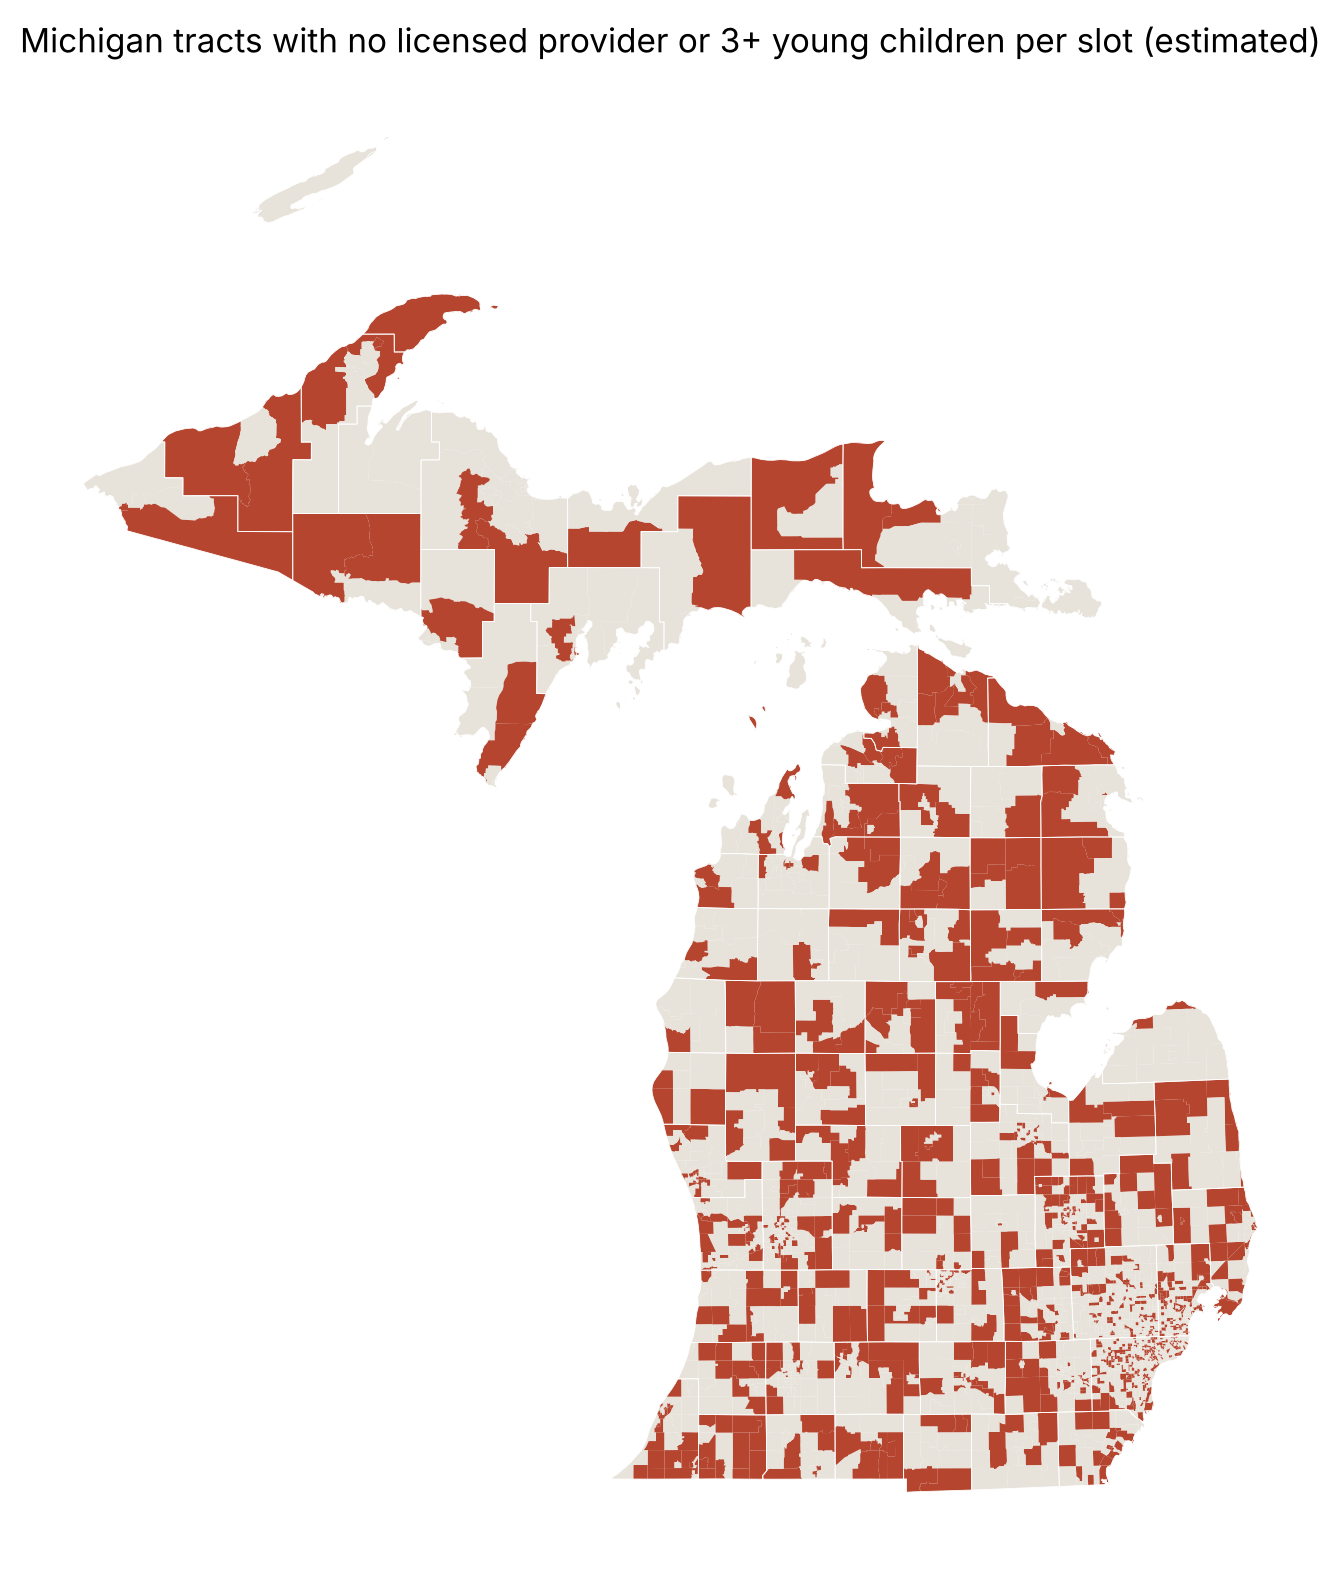

In [14]:
if HAVE_TRACTS:
    within = (t.groupby("county").apply(lambda d: pd.Series({
                  "tracts": len(d),
                  "kids in thin tracts": d.loc[d["thin"], "kids_under5"].sum() / d["kids_under5"].sum()}), include_groups=False)
              .reset_index())
    mi_t = mi.merge(within, left_on="GEOID", right_on="county", how="left")
    print(f"Corr(county licensed-slot score, share of kids in thin tracts): "
          f"{mi_t['lic_score_mi'].rank().corr(mi_t['kids in thin tracts'].rank()):.2f}")
    show = mi_t.nsmallest(10, "rank_lic_mi")[["rank_lic_mi", "county_name", "kids_per_slot_eb", "tracts", "kids in thin tracts"]]
    display(show.round(2))
    t.to_csv(ROOT / "data/processed/mi_tracts_licensed.csv", index=False)

    fig, ax = plt.subplots(figsize=(7, 8))
    g = tracts.merge(t[["GEOID", "thin"]], on="GEOID", how="left")
    g.plot(ax=ax, color=np.where(g["thin"] == True, "#B5452F", "#E7E2DA"), linewidth=0)
    counties.boundary.plot(ax=ax, color="white", linewidth=0.3)
    ax.set_axis_off(); ax.set_title("Michigan tracts with no licensed provider or 3+ young children per slot (estimated)")
    fig.tight_layout(); fig.savefig(FIG / "04_mi_thin_tracts.png", dpi=150); plt.show()

## What this means

**Data.** The state's licensing file has its county and capacity columns attached to the wrong providers (only 5.8% of county labels match the map point). They were shuffled together, so county totals of licensed slots are still right, and notebook 03's check, which used county totals, stands. Capacity for an individual provider cannot be trusted, so tract-level capacity has to be estimated (section 5).

**Agreement.** Inside Michigan the two shortage measures rank counties with a correlation of 0.62 (metro 0.62, rural 0.59). They agree on 13 of the 20 worst counties. Agreement drops to 0.22 in the 12 counties where the Census withholds business data, and the two measures share none of the 3 worst there. The national measure is a rough guide for Michigan and is weakest in withheld counties, which supports flagging those counties' results as unconfirmed.

**Why they disagree.** The gaps come from the worker count, not the child count. Where the national measure looks much worse than licensed slots (Clare, Dickinson, Oceana, Gladwin), the Census counts 16 to 30 licensed slots per childcare worker, against a Michigan median of 12. That is too few workers for the slots that exist. Part of the reason is school-run programs: their staff are school employees, so childcare business counts never see them. The share of school-run providers lines up with the gap (0.21), and it is high in Clare (30%), Oceana (35%) and Gladwin (24%). The opposite cases (Clinton, Delta, Mecosta) count more workers than the licensed slots would need (5 to 8 slots per worker). That points to care outside licensing, such as license-exempt or school-age programs. The home-based share and the Census self-employed count explain little.

**Candidates.** The Michigan combined ranks under the two measures correlate at 0.76, and 10 of the top 15 are the same. Lake, Iron, Crawford, Cheboygan, Ogemaw and Luce sit near the top either way, so they are the most robust Michigan candidates. Clare, Dickinson and Otsego drop out under licensed slots; St. Clair, Mecosta and Lapeer come in.

**Inside counties (estimated).** Providers placed in census tracts show that 16% of Michigan tracts with young children have no licensed provider. 35% of Michigan's children under 5 live in a tract with no provider or with 3 or more children per estimated slot. Counties that score worse on licensed slots also have more of their children in these thin tracts (correlation 0.46). In Lake and Crawford, 73% of young children live in thin tracts, so the shortage covers most of the county rather than a few pockets. Tract slots are estimates (section 5), so read these as patterns, not counts.